In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.metrics import classification_report, confusion_matrix, fbeta_score, roc_auc_score, precision_recall_curve, auc

In [24]:
#Importar datos

# fetch dataset 
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) 
  
# data (as pandas dataframes) 
X = breast_cancer_wisconsin_diagnostic.data.features 
y = breast_cancer_wisconsin_diagnostic.data.targets


y.info()

y["Diagnosis"] = y["Diagnosis"].map({"M": 1, "B": 0})

# metadata 
print(breast_cancer_wisconsin_diagnostic.metadata) 
  
# variable information 
print(breast_cancer_wisconsin_diagnostic.variables) 


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Diagnosis  569 non-null    str  
dtypes: str(1)
memory usage: 4.6 KB
{'uci_id': 17, 'name': 'Breast Cancer Wisconsin (Diagnostic)', 'repository_url': 'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic', 'data_url': 'https://archive.ics.uci.edu/static/public/17/data.csv', 'abstract': 'Diagnostic Wisconsin Breast Cancer Database.', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 569, 'num_features': 30, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Diagnosis'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1993, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5DW2B', 'creators': ['William Wolberg', 'Olvi Mangasarian', 'Nick Street', 'W. S

In [5]:
#Exploración Inicial
X.describe().T

,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture1,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter1,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area1,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness1,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness1,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity1,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points1,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry1,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension1,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


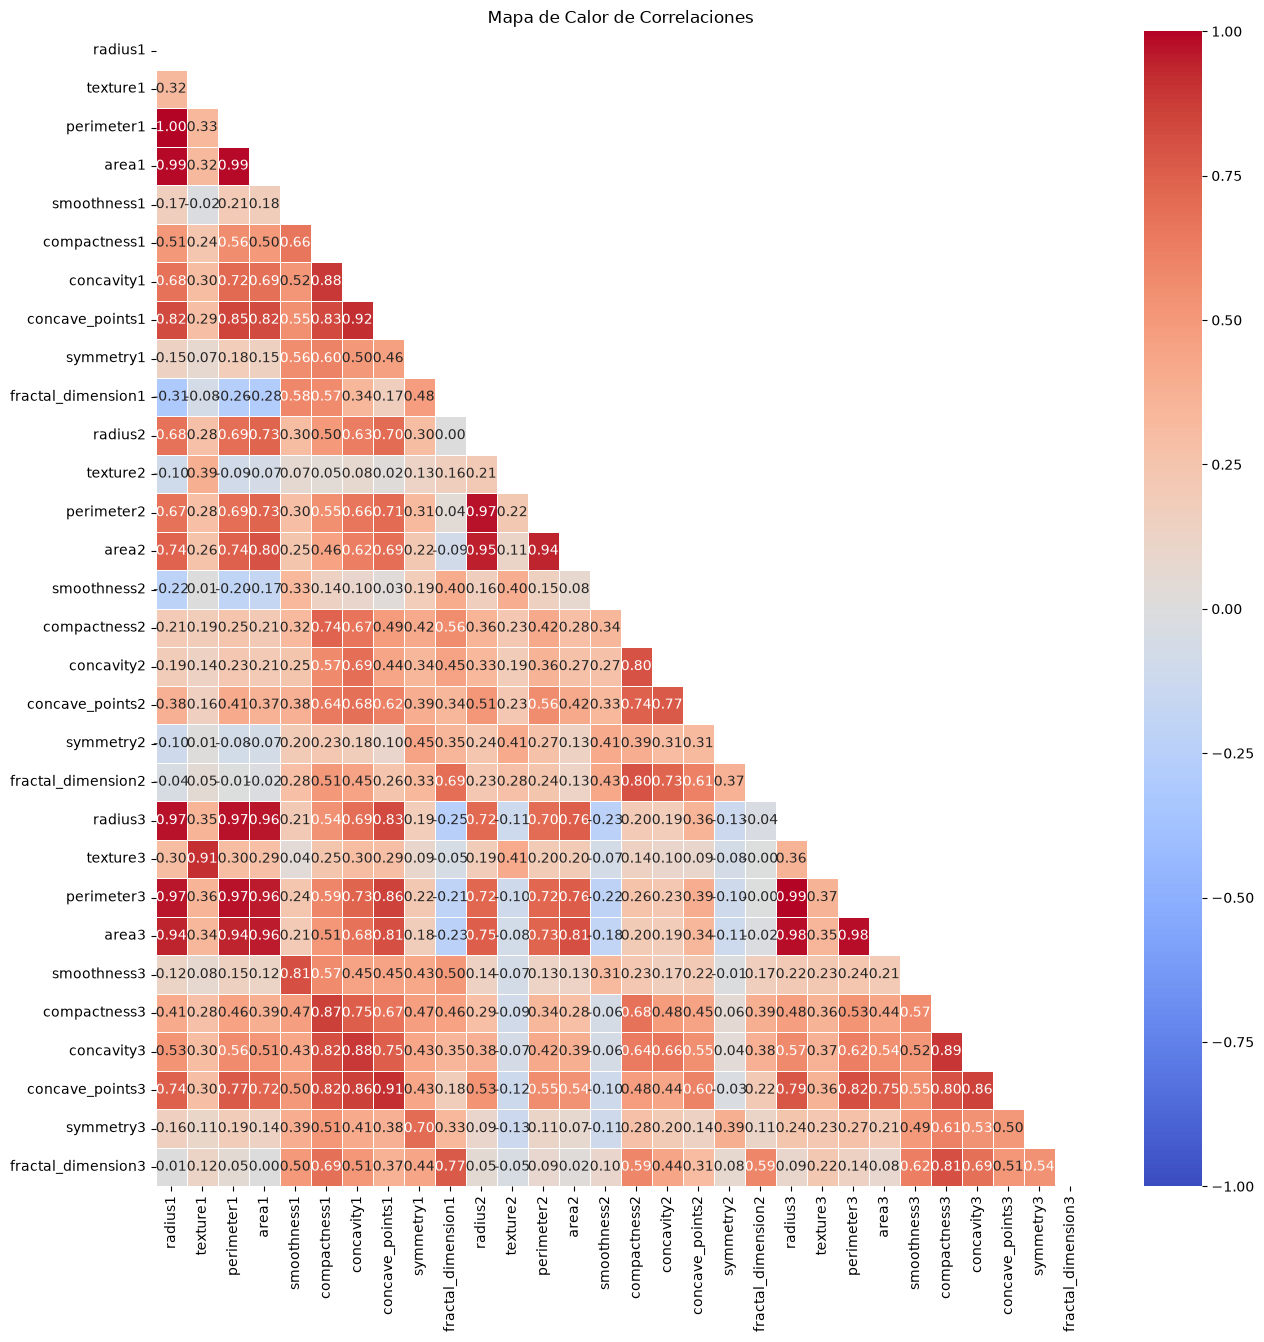

In [7]:
# 1. Generar matriz de correlación
matriz_corr = X.corr(method="pearson")

# 2. Representación mediante Heatmap
plt.figure(figsize=(15, 15))
# MÁSCARA para ocultar la mitad superior simétrica redundante
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))

sns.heatmap(
    matriz_corr, 
    mask=mascara,
    annot=True,          # Muestra el valor numérico
    fmt=".2f",           # Formato de dos decimales
    cmap="coolwarm",     # Paleta divergente (rojo=positivo, azul=negativo)
    vmin=-1, vmax=1,     # Escala fija de correlación
    linewidths=0.5
)
plt.title("Mapa de Calor de Correlaciones")
plt.show()

In [26]:
# Preparar Dataset para entrenamiento y testeo

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    stratify=y,
    random_state=42,
)

c:\Users\Apky2\Desktop\Universidad\02. Cursos Ingeniería Informática\02. Tercero De Carrera\TPIA-EXP\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


0.9649122807017544


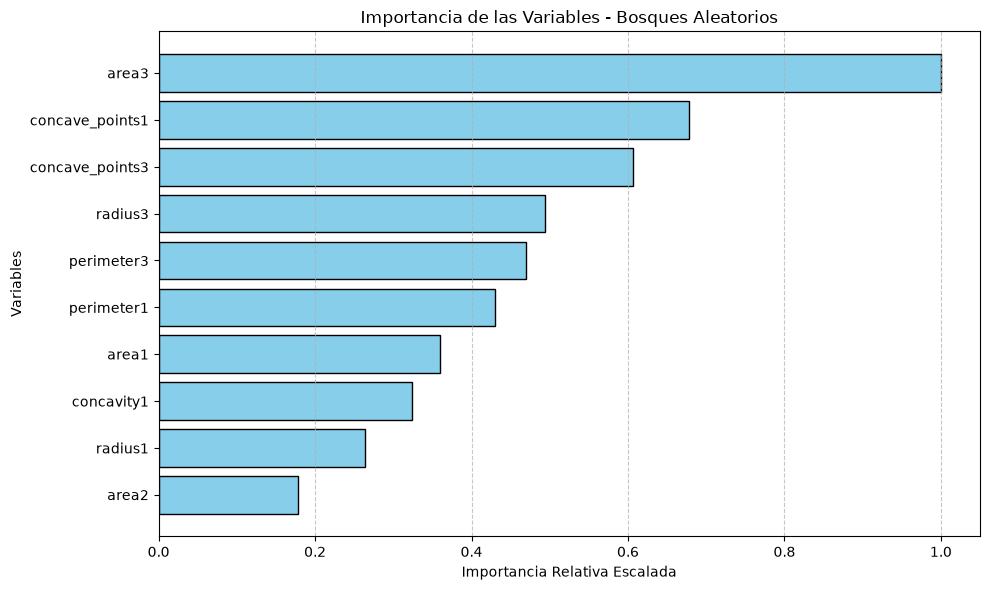

In [27]:
modelo_rf = RandomForestClassifier(
    n_estimators=100,         # Número de árboles en el bosque
    max_features="sqrt",      # Características evaluadas por división
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

score_rf = modelo_rf.score(X_test, y_test)
print(score_rf)

# Importancia relativa de las variables
importancias_rf = modelo_rf.feature_importances_
importances_rf = importancias_rf / np.max(importancias_rf)
indices = np.argsort(importances_rf)[::-1]

# Selección de las N variables más importantes
top_n = 10
indices_top = indices[:top_n]
indices_predictores = X.columns.values

# Graficamos el resultado
plt.figure(figsize=(10,6))
plt.barh(range(top_n), importances_rf[indices_top][::-1], color='skyblue', edgecolor='black')
plt.yticks(range(top_n), indices_predictores[indices_top][::-1])

plt.xlabel('Importancia Relativa Escalada')
plt.ylabel('Variables')
plt.title('Importancia de las Variables - Bosques Aleatorios')
plt.grid(axis='x', linestyle='--', alpha=0.7) # Añade líneas guía de fondo
plt.tight_layout()
plt.show()


In [28]:
# Definición del Pipeline
pipe = Pipeline([
    # ("scaler", StandardScaler()), No requierido en árboles
    ("classifier", RandomForestClassifier(random_state=42))
])

# Espacio de hiperparámetros (sintaxis: nombrepaso__nombreparametro)
param_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [4, 5, 6, 7, 8],
    "classifier__min_samples_split": [2, 4, 6, 8, 10],
    "classifier__min_samples_leaf": [2, 3, 5],
}

# Validación Cruzada Estratificada
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Búsqueda exhaustiva optimizando por la métrica de interés (ej. recall, f2, roc_auc)
grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring="roc_auc",       # O 'recall', 'f1', 'f2' según el dominio
    cv=cv_estratificado,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print(f"Mejor combinación: {grid_search.best_params_}")
print(f"Mejor puntuación de CV: {grid_search.best_score_:.4f}")

Mejor combinación: {'classifier__max_depth': 4, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 6, 'classifier__n_estimators': 50}
Mejor puntuación de CV: 0.9857


c:\Users\Apky2\Desktop\Universidad\02. Cursos Ingeniería Informática\02. Tercero De Carrera\TPIA-EXP\.venv\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [32]:
# Obtener las probabilidades predichas del mejor modelo
mejor_modelo = grid_search.best_estimator_
y_probs = mejor_modelo.predict_proba(X_test)[:, 1]

# Ajustar manualmente el umbral de decisión
umbral_personalizado = 0.05  # Al bajar el umbral, se incrementa el Recall

# Generar nuevas predicciones basadas en el umbral ajustado
y_pred_ajustado = (y_probs >= umbral_personalizado).astype(int)

# Imprimir la matriz de confusión
print(confusion_matrix(y_test, y_pred_ajustado))

# ROC-AUC
score_roc = roc_auc_score(y_test, y_probs)

# PR-AUC
precisiones, recalls, umbrales = precision_recall_curve(y_test, y_probs)
score_pr_auc = auc(recalls, precisiones)

print(f"ROC-AUC: {score_roc:.4f} | PR-AUC: {score_pr_auc:.4f}")


# ROC-AUC
score_roc_ad = roc_auc_score(y_test, y_pred_ajustado)

# PR-AUC
precisiones, recalls, umbrales = precision_recall_curve(y_test, y_pred_ajustado)
score_pr_auc = auc(recalls, precisiones)

print(f"ROC-AUC: {score_roc:.4f} | PR-AUC: {score_pr_auc:.4f}")

[[82 25]
 [ 0 64]]
ROC-AUC: 0.9930 | PR-AUC: 0.9901
ROC-AUC: 0.9930 | PR-AUC: 0.8596
